# **Module02: Univariate Descriptive Statistics**

---

## 📌 Overview

**Univariate Descriptive Statistics** consists of the set of techniques used to organize, summarize, and explore the behavior of **a single variable at a time**. Before investigating relationships between multiple variables or building predictive models, understanding the individual distribution of each attribute is essential for identifying patterns, detecting outliers, and validating statistical assumptions.

In this notebook, we will explore the main numerical indicators and visual tools that transform raw data into clear, actionable insights.

---

## 🎯 Learning Objectives

By the end of this module, you will be able to:

* **Summarize distributions** using frequency tables (absolute, relative, and cumulative).
* **Calculate and interpret measures of central tendency and position** (mean, median, mode, quartiles, and percentiles), choosing the most appropriate one based on variable type and the presence of outliers.
* **Evaluate data variability** through measures of dispersion (range, variance, standard deviation, interquartile range, and coefficient of variation).
* **Analyze distribution shape** using measures of skewness and kurtosis.
* **Build and interpret univariate visualizations** (bar charts, histograms, density plots, and boxplots).

---

## 🧭 Module Structure

1. **Frequency Tables** — Organizing qualitative and quantitative variables (class intervals / binning).
2. **Measures of Central Tendency and Position** — Where the data is concentrated.
3. **Measures of Dispersion** — How much the data varies around the center.
4. **Measures of Shape** — Symmetry and tailedness of the distribution.
5. **Univariate Graphical Analysis** — Visual diagnostics of distributions and outliers.
6. **Hands-on Python** — Complete practical application using `pandas`, `numpy`, `scipy.stats`, `matplotlib`, and `seaborn`.

---

## 🛠️ Technical Requirements

* Prior knowledge of **Variable Types and Measurement Scales** (*Module01*).
* Python environment configured with: `numpy`, `pandas`, `scipy`, `matplotlib`, and `seaborn`.

In [1]:
# First, we need to install the required libraries
%pip install pandas numpy matplotlib seaborn statistics scipy statsmodels scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import libraries
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
import statistics as st
import scipy.stats as stats
from scipy.stats import skewnorm, skew, kurtosis

In [3]:
import sys
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import scipy
import statsmodels
import sklearn

print(f"Python:       {sys.version.split()[0]}")
print(f"Pandas:       {pd.__version__}")
print(f"NumPy:        {np.__version__}")
print(f"Matplotlib:   {matplotlib.__version__}")
print(f"Seaborn:      {sns.__version__}")
print(f"SciPy:        {scipy.__version__}")
print(f"Statsmodels:  {statsmodels.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")

Python:       3.12.3
Pandas:       3.1.1
NumPy:        2.5.5
Matplotlib:   3.11.2
Seaborn:      0.13.2
SciPy:        1.18.1
Statsmodels:  0.15.0
Scikit-learn: 1.9.1


## **Frequency Distribution Table**

These tables show the occurrence of each value (or class) in a set of observations of qualitative or quantitative variables.

* `Absolute frequency` ($f_i$): number of occurrences of each element $i$
* `Relative frequency` ($f_{ri}$): percentage corresponding to the absolute frequency
* `Cumulative frequency` ($f_{ac}$): sum of occurrences up to the analyzed element
* `Cumulative relative frequency` ($f_{rac}$): percentage corresponding to the cumulative frequency

## **Frequency Distribution Table: Qualitative Case**

In [4]:
donors = pd.DataFrame([
    ["A+", 15],
    ["A-", 2],
    ["B+", 6],
    ["B-", 1],
    ["AB+", 1],
    ["AB-", 1],
    ["O+", 32],
    ["O-", 2]
])

columns = ["Blood Type", "Donors"]

donors.columns = columns
donors

,Blood Type,Donors
0,A+,15
1,A-,2
2,B+,6
3,B-,1
4,AB+,1
5,AB-,1
6,O+,32
7,O-,2


In [5]:
# Absolute frequency
donors["f_i"] = donors.Donors
sum_fi = sum(donors["f_i"])

# Relative frequency
donors["f_ri"] = np.round(donors.Donors / sum_fi * 100, 2)
sum_fri = sum(donors["f_ri"])

# Cumulative frequency
donors["f_ac"] = donors.Donors.cumsum()

# Cumulative relative frequency
donors["f_rac"] = np.round(donors["f_ri"].cumsum(), 2)

print(f"Sum of Absolute Frequency: {sum_fi}")
print(f"Sum of Relative Frequency: {np.round(sum_fri, 2)} %")
print(" ")
donors

Sum of Absolute Frequency: 60
Sum of Relative Frequency: 100.0 %
 


,Blood Type,Donors,f_i,f_ri,f_ac,f_rac
0,A+,15,15,25.00,15,25.00
1,A-,2,2,3.33,17,28.33
2,B+,6,6,10.00,23,38.33
3,B-,1,1,1.67,24,40.00
4,AB+,1,1,1.67,25,41.67
5,AB-,1,1,1.67,26,43.34
6,O+,32,32,53.33,58,96.67
7,O-,2,2,3.33,60,100.00


## **Frequency Distribution Table: Quantitative Case**

Here, the values are sorted from smallest to largest before accumulating the frequencies.

In [6]:
people_list = pd.DataFrame([2, 5, 4, 7, 4, 1, 6, 2, 2, 5, 4, 12,
                            8, 6, 4, 5, 2, 8, 6, 4, 5, 2, 2, 2,
                            4, 7, 2, 5, 6, 4, 1, 5, 10, 2, 2, 10,
                            2, 10, 6, 4, 3, 4, 6, 3, 8, 4, 2, 1])

In [7]:
# Absolute frequency (sorted values)
counts = people_list[0].value_counts().sort_index().to_frame()
counts.columns = ["f_i"]
counts.index.name = "People"
sum_fi = sum(counts["f_i"])

# Relative frequency
counts["f_ri"] = np.round(counts["f_i"] / sum_fi * 100, 2)
sum_fri = sum(counts["f_ri"])

# Cumulative frequency
counts["f_ac"] = counts["f_i"].cumsum()

# Cumulative relative frequency
counts["f_rac"] = np.round(counts["f_ri"].cumsum(), 2)

print(f"Sum of Absolute Frequency: {sum_fi}")
print(f"Sum of Relative Frequency: {np.round(sum_fri, 2)} %")
print(" ")
counts

Sum of Absolute Frequency: 48
Sum of Relative Frequency: 100.0 %
 


,f_i,f_ri,f_ac,f_rac
People,,,,
1,3,6.25,3,6.25
2,12,25.00,15,31.25
3,2,4.17,17,35.42
4,10,20.83,27,56.25
5,6,12.50,33,68.75
6,6,12.50,39,81.25
7,2,4.17,41,85.42
8,3,6.25,44,91.67
10,3,6.25,47,97.92


## **Graphical Representation of Results**

### **Bar Chart**

In [8]:
data = pd.DataFrame([
    ["Excellent", 58],
    ["Good", 18],
    ["Fair", 32],
    ["Poor", 12]
])
data.columns = ["Satisfaction", "Absolute Frequency"]
data

,Satisfaction,Absolute Frequency
0,Excellent,58
1,Good,18
2,Fair,32
3,Poor,12


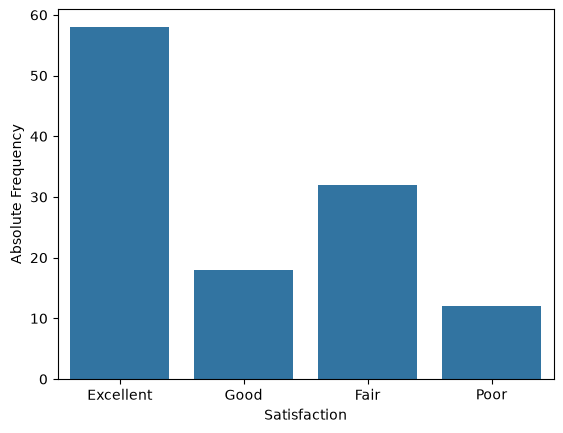

In [9]:
# Vertical bar chart
fig, ax = plt.subplots()
ax = sns.barplot(x="Satisfaction", y="Absolute Frequency", data=data)

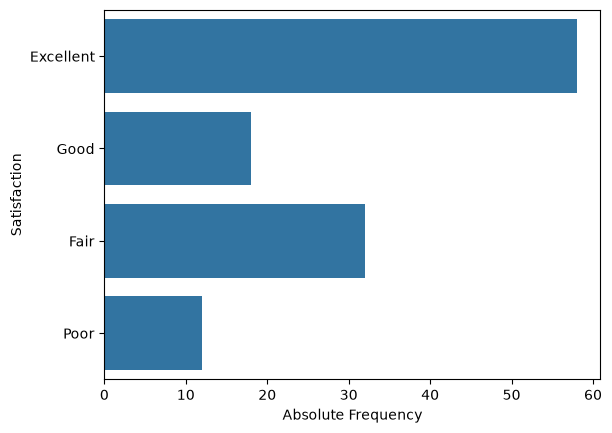

In [10]:
# Horizontal bar chart
fig, ax = plt.subplots()
ax = sns.barplot(y="Satisfaction", x="Absolute Frequency", data=data)

### **Pie Chart**

In [11]:
data = pd.DataFrame([
    ["PMDB", 18],
    ["REDE", 22],
    ["PDT", 12],
    ["PSDB", 25],
    ["PC do B", 8],
    ["PV", 5],
    ["Others", 10]
])

data.columns = ["Party", "Percentage"]
data = data.sort_values("Percentage", ascending=False)
data

,Party,Percentage
3,PSDB,25
1,REDE,22
0,PMDB,18
2,PDT,12
6,Others,10
4,PC do B,8
5,PV,5


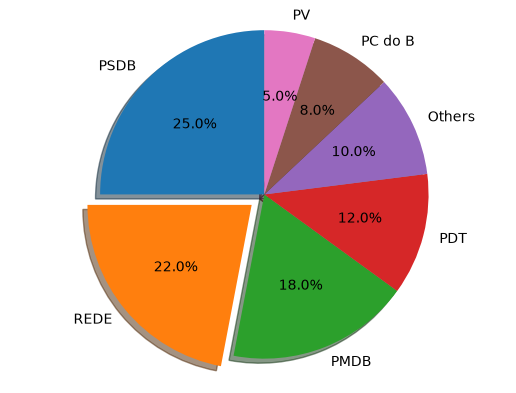

In [12]:
# Pie chart
fig, ax = plt.subplots()
ax.pie(data["Percentage"], labels=data["Party"], autopct="%1.1f%%",
       shadow=True, explode=(0, 0.1, 0, 0, 0, 0, 0), startangle=90)
ax.axis("equal")
plt.show()

### **Pareto Chart**

Combines a bar chart, with categories sorted in descending order of frequency, and a line showing the cumulative percentage. It helps identify the few categories that concentrate most of the occurrences.

In [13]:
from matplotlib.ticker import PercentFormatter

In [14]:
data["Cumulative Percentage"] = data["Percentage"].cumsum()
data

,Party,Percentage,Cumulative Percentage
3,PSDB,25,25
1,REDE,22,47
0,PMDB,18,65
2,PDT,12,77
6,Others,10,87
4,PC do B,8,95
5,PV,5,100


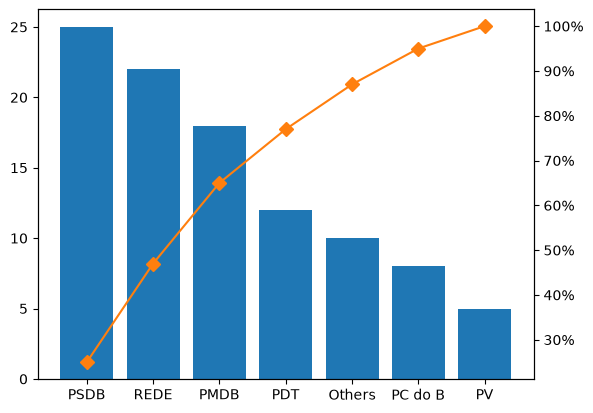

In [15]:
fig, ax = plt.subplots()

ax.bar(data["Party"], data["Percentage"])
ax2 = ax.twinx()

ax2.plot(data["Party"], data["Cumulative Percentage"], color="C1", marker="D", ms=7)
ax2.yaxis.set_major_formatter(PercentFormatter())

ax.tick_params(axis="y")
ax2.tick_params(axis="y")
plt.show()

### **Line Chart**

In [16]:
monthly_losses = pd.DataFrame([
    ["January", 0.42],
    ["February", 0.38],
    ["March", 0.12],
    ["April", 0.34],
    ["May", 0.22],
    ["June", 0.15],
    ["July", 0.18],
    ["August", 0.31],
    ["September", 0.47],
    ["October", 0.24],
    ["November", 0.42],
    ["December", 0.09]
])

monthly_losses.columns = ["Month", "Losses"]
monthly_losses

,Month,Losses
0,January,0.42
1,February,0.38
2,March,0.12
3,April,0.34
4,May,0.22
5,June,0.15
6,July,0.18
7,August,0.31
8,September,0.47
9,October,0.24


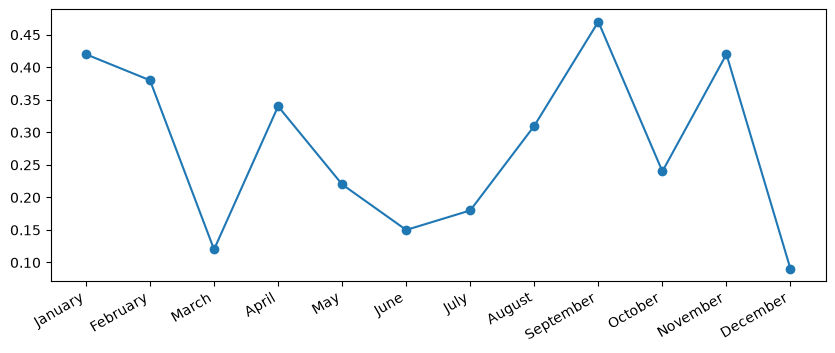

In [17]:
# Line chart
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly_losses["Month"], monthly_losses["Losses"], marker='o')
ax.figure.autofmt_xdate()
plt.show()

### **Scatter Plot**

In [18]:
data = pd.DataFrame([
    [30, 250],
    [50, 255],
    [85, 252],
    [106, 248],
    [138, 250],
    [178, 249],
    [198, 252],
    [222, 251],
    [250, 250],
    [297, 245]
])

data.columns = ["Time", "Weight"]
data

,Time,Weight
0,30,250
1,50,255
2,85,252
3,106,248
4,138,250
5,178,249
6,198,252
7,222,251
8,250,250
9,297,245


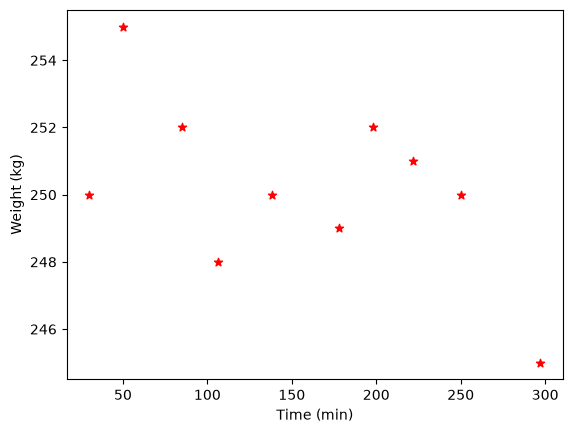

In [19]:
fig, ax = plt.subplots()
ax.scatter(data["Time"], data["Weight"], marker='*', color='red')
ax.set_xlabel("Time (min)")
ax.set_ylabel("Weight (kg)")
plt.show()

### **Histogram**

This is one of the most important charts in data analysis and essentially represents the frequencies of a **QUANTITATIVE** variable.

In [20]:
# People count data
counts

,f_i,f_ri,f_ac,f_rac
People,,,,
1,3,6.25,3,6.25
2,12,25.00,15,31.25
3,2,4.17,17,35.42
4,10,20.83,27,56.25
5,6,12.50,33,68.75
6,6,12.50,39,81.25
7,2,4.17,41,85.42
8,3,6.25,44,91.67
10,3,6.25,47,97.92


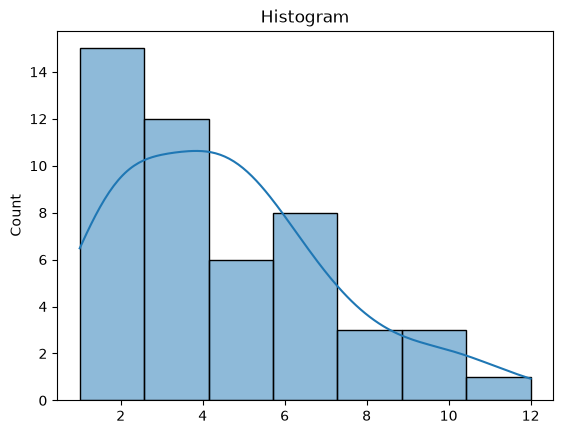

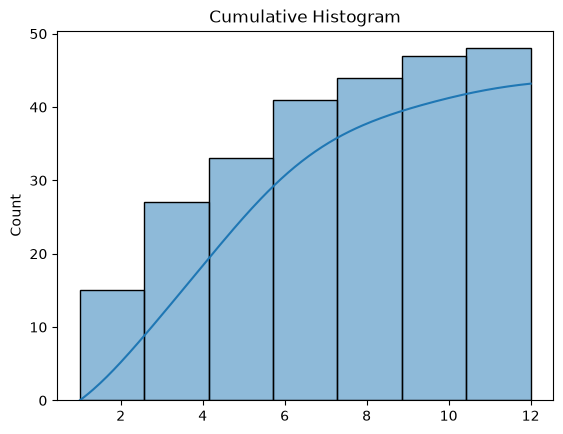

In [21]:
fig, ax = plt.subplots()
ax.set_title("Histogram")
ax = sns.histplot(people_list, kde=True, cumulative=False, bins='auto', legend=False)

fig, ax = plt.subplots()
ax.set_title("Cumulative Histogram")
ax = sns.histplot(people_list, kde=True, cumulative=True, bins='auto', legend=False)
plt.show()

### **Stem-and-Leaf Plot**

Organizes sorted data by splitting each value into a stem (here, the tens digit) and a leaf (the units digit). It shows the shape of the distribution like a histogram, but without losing the original values.

In [22]:
ages = pd.DataFrame([44, 60, 22, 49, 31, 58, 42, 63, 33, 37,
                     54, 55, 40, 71, 55, 62, 35, 45, 59, 54,
                     50, 51, 24, 31, 40, 73, 28, 35, 75, 48])
ages.columns = ["Employees"]
ages = ages.sort_values("Employees")

In [23]:
def stem_and_leaf(values):
    # Stem = tens, leaf = units
    values = sorted(values)
    stems = {}
    for v in values:
        stems.setdefault(v // 10, []).append(v % 10)

    for stem, leaves in stems.items():
        print(f"{stem:>2} | {' '.join(str(leaf) for leaf in leaves)}")

stem_and_leaf(ages["Employees"].values)

 2 | 2 4 8
 3 | 1 1 3 5 5 7
 4 | 0 0 2 4 5 8 9
 5 | 0 1 4 4 5 5 8 9
 6 | 0 2 3
 7 | 1 3 5


### **Box Plot**

Summarizes the distribution using quartiles: the box spans from $Q_1$ to $Q_3$, the inner line represents the median, and points outside the whiskers ($Q_1 - 1.5\cdot IQR$ and $Q_3 + 1.5\cdot IQR$) are potential outliers.

In [24]:
ages = pd.DataFrame([44, 60, 22, 49, 31, 58, 42, 63, 33, 37,
                     54, 55, 40, 71, 55, 62, 35, 45, 59, 54,
                     50, 51, 24, 31, 40, 73, 28, 35, 75, 48])
ages.columns = ["Employees"]
ages = ages.sort_values("Employees")

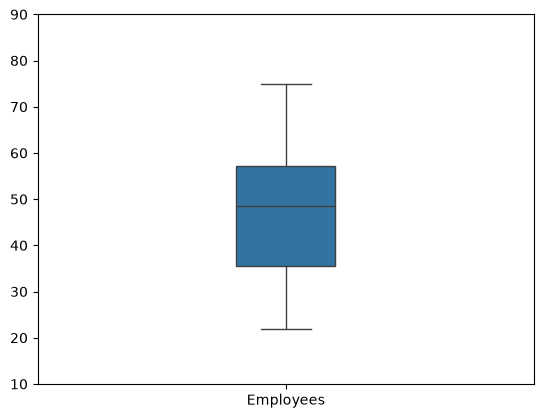

In [25]:
fig, ax = plt.subplots()
sns.boxplot(data=ages, width=0.2, orient='v', ax=ax)
ax.set_ylim([10, 90])
plt.show()

## **Summary Measures (Descriptive Statistics)**

* `Measures of position or location:` in general, they indicate where the data lie along the value axis. They are divided into measures of central tendency (mean, median, mode) and partition values/quantiles (quartiles, deciles, and percentiles).

* `Measures of dispersion or variability:` indicate how much the data vary, including range, mean absolute deviation, variance, standard deviation, standard error, and coefficient of variation.

* `Measures of shape:` describe the shape of the distribution (skewness and kurtosis).

### **Measures of Position**

#### **Arithmetic Mean**

$\overline{X} = \frac{\sum_{i=1}^{n}X_i}{n}$

In [26]:
values = [5.7, 6.5, 6.9, 8.3, 8, 4.2, 6.3, 7.4, 5.8, 6.0]
print(f"Mean value: {np.mean(values)}")

Mean value: 6.51


#### **Weighted Arithmetic Mean**

Each value $X_i$ is assigned a weight $p_i$.

$\overline{X} = \frac{\sum_{i=1}^{n}X_i\cdot p_i}{\sum_{i=1}^{n}p_i}$

In [27]:
returns = [4.5, 7.0, 5.5, 6.5]
weights = [1, 2, 3, 4]

weighted_mean = np.round(np.average(returns, weights=weights), 2)
print(f"Weighted mean value: {weighted_mean}")

Weighted mean value: 6.1


#### **Median**

The value that divides an ordered series into two equal halves.

`If n is even:`
$M_d = \frac{X_{(\frac{n}{2})}+X_{(\frac{n}{2}+1)}}{2}$

`If n is odd:`
$M_d = X_{(\frac{n+1}{2})}$

In [28]:
monthly_losses = monthly_losses.sort_values("Losses", ascending=False)
monthly_losses

,Month,Losses
8,September,0.47
0,January,0.42
10,November,0.42
1,February,0.38
3,April,0.34
7,August,0.31
9,October,0.24
4,May,0.22
6,July,0.18
5,June,0.15


In [29]:
print(f"Median value: {st.median(monthly_losses.Losses)}")

Median value: 0.275


#### **Mode**
The value that occurs most frequently in a series.

In [30]:
print(f"Mode value: {st.mode(monthly_losses.Losses)}")

Mode value: 0.42


### **Partition Values (Quantiles)**

They divide the ordered series into equal parts: quartiles into 4, deciles into 10, and percentiles into 100.

#### **Quartiles**

In [31]:
total_losses = np.round(sum(monthly_losses["Losses"]), 2)
print(f"Total losses in the year: {total_losses}")

Total losses in the year: 3.34


In [32]:
q = np.round(monthly_losses["Losses"].quantile(q=0.25), 2)
print(f"Q1: {q}")

q = np.round(monthly_losses["Losses"].quantile(q=0.50), 2)
print(f"Q2: {q}")

q = np.round(monthly_losses["Losses"].quantile(q=0.75), 2)
print(f"Q3: {q}")

Q1: 0.17
Q2: 0.28
Q3: 0.39


In general, quartiles are the most commonly used. `Q1` means that *25%* of the analyzed months had losses below 0.17, `Q2` (the median) means that *50%* of the months had losses below 0.28, and `Q3` means that in *75%* of the months, the loss was below 0.39.

`NOTE:` *Deciles and percentiles follow the exact same logic.*

#### **Deciles**

In [33]:
for i in range(1, 10):
    q = np.round(monthly_losses["Losses"].quantile(q=i / 10), 2)
    print(f"D{i}: {q}")

D1: 0.12
D2: 0.16
D3: 0.19
D4: 0.23
D5: 0.28
D6: 0.33
D7: 0.37
D8: 0.41
D9: 0.42


#### **Percentiles**

In [34]:
q = np.round(monthly_losses["Losses"].quantile(q=0.25), 2)
print(f"P25: {q}")

q = np.round(monthly_losses["Losses"].quantile(q=0.50), 2)
print(f"P50: {q}")

q = np.round(monthly_losses["Losses"].quantile(q=0.75), 2)
print(f"P75: {q}")

P25: 0.17
P50: 0.28
P75: 0.39


#### **Outlier Detection**

Outliers are observations that lie far away from the rest—atypical, discrepant, abnormal, or extreme values.

*Example: in a sample of salaries at a company where most employees earn between 3 and 10 minimum wages, an executive earning 50 minimum wages is an outlier.*

`Detection methods:` box plot, discordance models, Dixon's test, Grubbs' test, Z-score...

Using the box-plot criterion, where $IQR = Q_3 - Q_1$ is the interquartile range, the fences for moderate outliers are $Q_1 - 1.5\cdot IQR$ and $Q_3 + 1.5\cdot IQR$, and for extreme outliers $Q_1 - 3\cdot IQR$ and $Q_3 + 3\cdot IQR$.

In [35]:
time_df = pd.DataFrame([44.0, 44.5, 44.7, 44.8, 44.9, 44.9, 45, 45, 45,
                        45, 45.4, 45.6, 45.7, 45.8, 46, 46.2, 46.2, 46.3, 46.5])
time_df.columns = ["time"]
time_df = time_df.sort_values("time")

In [36]:
def check_moderate_outliers(data):
    # Calculate quartiles
    q1 = data.quantile(q=0.25)
    q2 = data.quantile(q=0.50)
    q3 = data.quantile(q=0.75)

    # Create results DataFrame
    result = pd.DataFrame([])

    # Calculate interquartile range
    iqr = q3 - q1

    # Check fences
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    result["Max"] = data.max()
    result["Min"] = data.min()
    result["Lower"] = lower_bound
    result["Upper"] = upper_bound
    result["IQR"] = iqr
    result["Q1"] = q1
    result["Q2"] = q2
    result["Q3"] = q3

    return result

In [37]:
check_moderate_outliers(time_df)

,Max,Min,Lower,Upper,IQR,Q1,Q2,Q3
time,46.5,44.0,43.4,47.4,1.0,44.9,45.0,45.9


Since both `Max` and `Min` fall within the interval between `Lower` and `Upper`, there are no moderate outliers.

In [38]:
def check_extreme_outliers(data):
    # Calculate quartiles
    q1 = data.quantile(q=0.25)
    q2 = data.quantile(q=0.50)
    q3 = data.quantile(q=0.75)

    # Create results DataFrame
    result = pd.DataFrame([])

    # Calculate interquartile range
    iqr = q3 - q1

    # Check fences
    lower_bound = q1 - 3 * iqr
    upper_bound = q3 + 3 * iqr

    result["Max"] = data.max()
    result["Min"] = data.min()
    result["Lower"] = lower_bound
    result["Upper"] = upper_bound
    result["IQR"] = iqr
    result["Q1"] = q1
    result["Q2"] = q2
    result["Q3"] = q3

    return result

In [39]:
check_extreme_outliers(time_df)

,Max,Min,Lower,Upper,IQR,Q1,Q2,Q3
time,46.5,44.0,41.9,48.9,1.0,44.9,45.0,45.9


As expected, there are no extreme outliers either. In practice, if no moderate outliers are found, this second check is not even necessary.

### **Measures of Dispersion**

#### **Range**

The simplest measure of dispersion: the difference between the largest and smallest observed values.

$R = X_{\max} - X_{\min}$

In [40]:
data = [12.4, 22.6, 19.9, 9.7, 14.5, 22.5, 26.3, 17.7, 31.2, 20.4]

In [41]:
data_range = max(data) - min(data)
data_range

21.5

#### **Mean Absolute Deviation**

The average of the absolute deviations of each observed value from the mean.

* For a population:
$MAD = \frac{\sum_{i=1}^{N}|X_i-\mu|}{N}$

* For a sample:
$MAD = \frac{\sum_{i=1}^{n}|X_i-\overline{X}|}{n}$

In [42]:
# Calculate mean absolute deviation
(time_df - time_df.mean()).abs().mean()

time    0.59169
dtype: float64

#### **Variance**
Measures the variability of the data around the arithmetic mean: the larger the variance, the greater the dispersion.

* For a population:
$\sigma^2 = \frac{\sum_{i=1}^{N}(X_i-\mu)^2}{N}$

* For a sample:
$S^2 = \frac{\sum_{i=1}^{n}(X_i-\overline{X})^2}{n - 1}$

In [43]:
# For a population of observations
st.pvariance(data)

37.6916

In [44]:
# For a sample of observations
st.variance(data)

41.879555555555555

#### **Standard Deviation**
Since variance is expressed in squared units of the original data—which makes interpretation harder—we take its square root to return to the original unit.

* For a population:
$\sigma = \sqrt{\sigma^2}$

* For a sample:
$S = \sqrt{S^2}$

In [45]:
# For a population of observations
st.pstdev(data)

6.139348499637401

In [46]:
# For a sample of observations
st.stdev(data)

6.471441536130536

#### **Standard Error**
Essentially the standard deviation of the sample mean: it indicates how much a sample mean tends to vary relative to the population mean.

* For a population:
$\sigma_{\overline{X}} = \frac{\sigma}{\sqrt{n}}$

* For a sample:
$S_{\overline{X}} = \frac{S}{\sqrt{n}}$

In [47]:
concrete_mix = [124, 111, 132, 142, 108, 127, 133, 144, 148, 105]
mixing_time = [124, 102, 135, 126, 132, 129, 156, 112, 108, 134,
               126, 104, 143, 140, 138, 129, 119, 114, 107, 121,
               124, 112, 148, 145, 130, 125, 120, 127, 106, 148]

In [48]:
std_mix = np.round(st.stdev(concrete_mix), 2)
std_mix

np.float64(15.36)

In [49]:
std_mixing_time = np.round(st.stdev(mixing_time), 2)
std_mixing_time

np.float64(14.23)

In [50]:
se_mix = np.round(std_mix / np.sqrt(len(concrete_mix)), 2)
se_mix

np.float64(4.86)

In [51]:
se_mixing_time = np.round(std_mixing_time / np.sqrt(len(mixing_time)), 2)
se_mixing_time

np.float64(2.6)

#### **Coefficient of Variation**
A relative measure of dispersion that expresses the variability of the data relative to the mean, as a percentage.

* For a population:
$CV = \frac{\sigma}{\mu}\cdot100$

* For a sample:
$CV = \frac{S}{\overline{X}}\cdot100$

In [52]:
cv_mix = np.round(std_mix / np.mean(concrete_mix) * 100, 2)
cv_mix

np.float64(12.06)

In [53]:
cv_mixing_time = np.round(std_mixing_time / np.mean(mixing_time) * 100, 2)
cv_mixing_time

np.float64(11.28)

### **Measures of Shape**
The most common measures of shape are skewness and kurtosis, which describe how values are distributed around the center of the distribution.

* `Skewness:` refers to the symmetry of the frequency distribution curve, which can be symmetric, right-skewed (positively skewed), or left-skewed (negatively skewed).

* `Kurtosis:` characterizes the tailedness/peakedness of the frequency distribution curve, which can be mesokurtic, platykurtic, or leptokurtic.

#### **Measures of Skewness**

In [54]:
np.random.seed(42)

symmetric_data = skewnorm.rvs(a=0, size=10000)
negative_skew_data = skewnorm.rvs(a=-4, size=10000)
positive_skew_data = skewnorm.rvs(a=10, size=10000)